# Customer Retention Analysis

## Purpose and scope
Explore how customer contract type and time with the company are associated with churn, and identify a retention initiative worth testing.

**Dataset:** IBM Telco Customer Churn, supplied as Telco_customer_churn.xlsx, containing 7,043 customer records and 33 original fields. Each row represents one customer. Churn Label identifies whether the customer left (Yes) or stayed (No).

**Source:** [IBM Telco Customer Churn on Kaggle](https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset). The source link follows the reference notebook supplied with this project.

This is an exploratory analysis of historical observations. It does not train a prediction model, establish a future churn horizon, or measure the effect of a retention campaign.

## How to run
Keep this notebook and Telco_customer_churn.xlsx in the same folder. Use a Python environment with pandas, openpyxl, matplotlib, and Jinja2 installed. If needed, install them in a notebook cell with `%pip install pandas openpyxl matplotlib jinja2`. Then restart the kernel and run cells from top to bottom. Saved charts and tables are included.

## 1 Load and inspect the data

Inspect dimensions, sample records, field types, customer ID uniqueness, and churn labels before making changes.

In [3]:
import pandas as pd

df = pd.read_excel("Telco_customer_churn.xlsx")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
# Column names, data types, and non-missing counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [5]:
# Check customer IDs and the outcome we want to understand
print("Duplicate customer IDs:", df["CustomerID"].duplicated().sum())

print("\nCustomer churn counts:")
print(df["Churn Label"].value_counts(dropna=False))

print("\nCustomer churn percentages:")
print(
    df["Churn Label"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Duplicate customer IDs: 0

Customer churn counts:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Customer churn percentages:
Churn Label
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Initial findings
- The workbook contains 7,043 customers, including 1,869 labeled as churned: **26.54%**.
- Customer IDs contain no duplicates in the supplied dataset.
- Total Charges is initially stored as text/object, so a non-missing count alone does not rule out blank strings.
- Churn Reason is populated only for the 1,869 churned customers. Those missing values are outcome-specific; they should not be filled with invented reasons for customers who stayed.
- Churn Score, Churn Value, CLTV, and other unrelated fields are not used in the contract and tenure comparisons.

## 2 Clean Total Charges

Preserve the original DataFrame, convert Total Charges to numeric, and inspect any values that become missing.

In [6]:
# Keep the original data intact
clean_df = df.copy()

# Convert charges to numbers; blanks or invalid text become NaN
original_charges = clean_df["Total Charges"].copy()

clean_df["Total Charges"] = pd.to_numeric(
    original_charges, errors="coerce"
)

# Inspect the affected customers
missing_charges = clean_df["Total Charges"].isna()

print("Customers with missing Total Charges:", missing_charges.sum())

clean_df.loc[
    missing_charges,
    ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges"]
]


Customers with missing Total Charges: 11


,CustomerID,Tenure Months,Monthly Charges,Total Charges
2234,4472-LVYGI,0,52.55,NaN
2438,3115-CZMZD,0,20.25,NaN
2568,5709-LVOEQ,0,80.85,NaN
2667,4367-NUYAO,0,25.75,NaN
2856,1371-DWPAZ,0,56.05,NaN
4331,7644-OMVMY,0,19.85,NaN
4687,3213-VVOLG,0,25.35,NaN
5104,2520-SGTTA,0,20.00,NaN
5719,2923-ARZLG,0,19.70,NaN
6772,4075-WKNIU,0,73.35,NaN


### Cleaning decision
Conversion identifies **11 missing Total Charges values**. All 11 customers have zero months of tenure. That is consistent with newly started accounts, but the dataset does not confirm why the charges are blank.

Retain the customers and leave Total Charges missing. The comparisons below use contract, tenure, customer ID, and churn, so missing cumulative charges do not prevent their inclusion. No zero charges or billing history are invented.

## 3 Compare churn by contract type
Map Yes to 1 and No to 0. The mean of this indicator is the proportion of customers labeled as churned. Compare rates rather than counts because contract groups have different sizes.

In [7]:
# Convert Yes/No into 1/0 so the average gives the churn rate
clean_df["Churn"] = clean_df["Churn Label"].map({"Yes": 1, "No": 0})

contract_summary = (
    clean_df.groupby("Contract")
    .agg(
        Customers=("CustomerID", "count"),
        Churned=("Churn", "sum"),
        Churn_Rate=("Churn", "mean")
    )
    .sort_values("Churn_Rate", ascending=False)
)

contract_summary.style.format({"Churn_Rate": "{:.1%}"})


,Customers,Churned,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.7%
One year,1473,166,11.3%
Two year,1695,48,2.8%


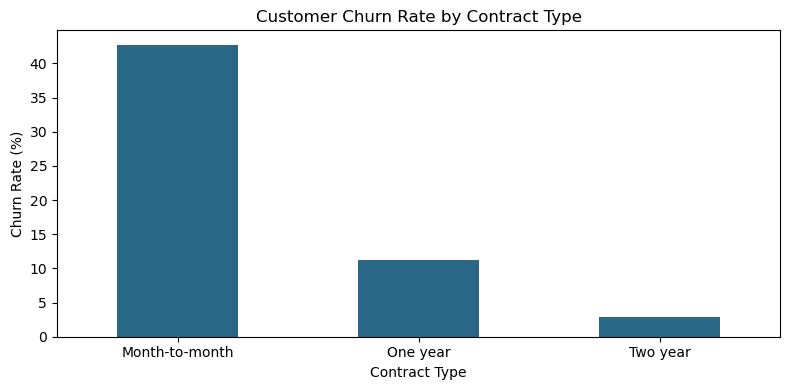

In [8]:
import matplotlib.pyplot as plt

ax = (contract_summary["Churn_Rate"] * 100).plot(
    kind="bar",
    color="#286785",
    figsize=(8, 4)
)

ax.set_title("Customer Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation
- Month-to-month: **42.7%**, or 1,655 of 3,875 customers.
- One year: **11.3%**, or 166 of 1,473 customers.
- Two year: **2.8%**, or 48 of 1,695 customers.

Month-to-month customers have the highest observed churn rate. The difference from two-year customers is **39.9 percentage points**. This association does not establish that a longer contract itself prevents churn; customer characteristics and contract selection may also matter.

## 4 Compare churn by tenure
Group observed tenure into 0–12, 13–24, 25–48, and 49+ months. The first interval includes zero tenure. Tenure is the value recorded in this historical dataset, not a prospectively followed cohort. The comparisons are descriptive rather than estimates of a future churn hazard.

In [9]:
# Group customers by how long they have been with the company
clean_df["Tenure_Group"] = pd.cut(
    clean_df["Tenure Months"],
    bins=[0, 12, 24, 48, float("inf")],
    labels=["0–12 months", "13–24 months", "25–48 months", "49+ months"],
    include_lowest=True
)

tenure_summary = (
    clean_df.groupby("Tenure_Group", observed=True)
    .agg(
        Customers=("CustomerID", "count"),
        Churned=("Churn", "sum"),
        Churn_Rate=("Churn", "mean")
    )
)

tenure_summary.style.format({"Churn_Rate": "{:.1%}"})

,Customers,Churned,Churn_Rate
Tenure_Group,,,
0–12 months,2186,1037,47.4%
13–24 months,1024,294,28.7%
25–48 months,1594,325,20.4%
49+ months,2239,213,9.5%


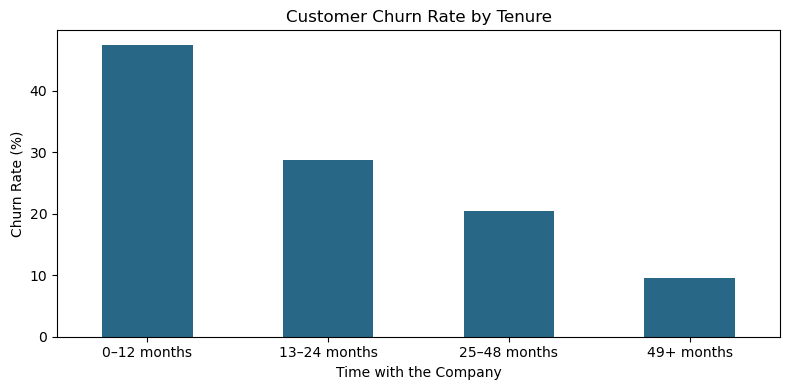

In [10]:
ax = (tenure_summary["Churn_Rate"] * 100).plot(
    kind="bar",
    color="#286785",
    figsize=(8, 4)
)

ax.set_title("Customer Churn Rate by Tenure")
ax.set_xlabel("Time with the Company")
ax.set_ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation
Observed churn decreases across the tenure groups: **47.4%**, **28.7%**, **20.4%**, and **9.5%**.

The 0–12 month group contains 2,186 customers and 1,037 churners. The 49+ month group contains 2,239 customers and 213 churners. The difference is **37.9 percentage points**.

This makes early customer experience a useful area to investigate. It does not prove that onboarding caused churn: customers who left early cannot accumulate long tenure, and longer-tenure groups reflect customers who remained.

## 5 Compare contracts within tenure groups
Cross-tabulate churn rates by both contract and tenure, then inspect the customer counts behind each percentage. This checks whether the broad contract pattern also appears within the chosen tenure bands. It is not a causal adjustment or statistical significance test.

In [11]:
# Calculate churn rates for each combination
churn_by_group = clean_df.pivot_table(
    index="Tenure_Group",
    columns="Contract",
    values="Churn",
    aggfunc="mean",
    observed=True
)

# Check how many customers support each rate
group_sizes = clean_df.pivot_table(
    index="Tenure_Group",
    columns="Contract",
    values="CustomerID",
    aggfunc="count",
    observed=True
)

display(churn_by_group.style.format("{:.1%}", na_rep="No customers"))
display(group_sizes)

Contract,Month-to-month,One year,Two year
Tenure_Group,,,
0–12 months,51.4%,10.5%,0.0%
13–24 months,37.7%,8.1%,0.0%
25–48 months,32.9%,10.6%,2.2%
49+ months,26.0%,12.9%,3.3%


Contract,Month-to-month,One year,Two year
Tenure_Group,,,
0–12 months,1994,124,68
13–24 months,737,197,90
25–48 months,802,518,274
49+ months,342,634,1263


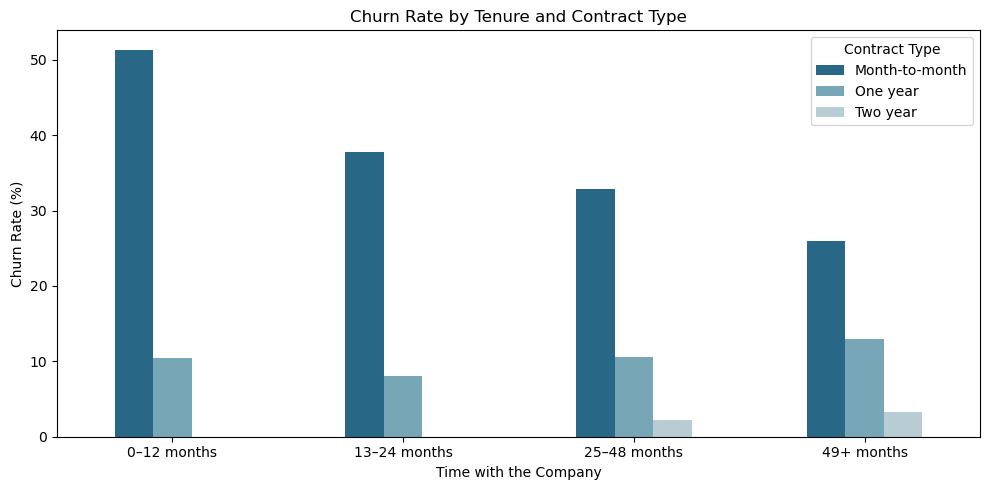

In [12]:
ax = (churn_by_group * 100).plot(
    kind="bar",
    figsize=(10, 5),
    color=["#286785", "#77A6B6", "#B7CCD3"]
)

ax.set_title("Churn Rate by Tenure and Contract Type")
ax.set_xlabel("Time with the Company")
ax.set_ylabel("Churn Rate (%)")
ax.legend(title="Contract Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation
Month-to-month contracts have the highest observed churn rate in every tenure band in this dataset.

Among customers with 0–12 months of tenure:
- Month-to-month: **51.4%** churn among **1,994** customers.
- One year: **10.5%** churn among **124** customers.
- Two year: **0.0%** churn among **68** customers.

The two-year group in the first band contains customers even though its chart bar is zero: no churn was recorded among those 68 customers. That small sample is not evidence that its underlying churn risk is zero. Group sizes differ considerably, so interpret comparisons with care.

## 6 Consolidated results

The tables below collect the counts and rates used in the findings. Churn_Rate is expressed as a proportion: 0.427 is approximately 42.7%.

In [13]:
print("CHURN BY CONTRACT")
print(contract_summary.round(3).to_string())

print("\nCHURN BY TENURE")
print(tenure_summary.round(3).to_string())

print("\nCUSTOMER COUNTS BY TENURE AND CONTRACT")
print(group_sizes.to_string())

CHURN BY CONTRACT
                Customers  Churned  Churn_Rate
Contract                                      
Month-to-month       3875     1655       0.427
One year             1473      166       0.113
Two year             1695       48       0.028

CHURN BY TENURE
              Customers  Churned  Churn_Rate
Tenure_Group                                
0–12 months        2186     1037       0.474
13–24 months       1024      294       0.287
25–48 months       1594      325       0.204
49+ months         2239      213       0.095

CUSTOMER COUNTS BY TENURE AND CONTRACT
Contract      Month-to-month  One year  Two year
Tenure_Group                                    
0–12 months             1994       124        68
13–24 months             737       197        90
25–48 months             802       518       274
49+ months               342       634      1263


## 7 Recommended business experiment
**Prioritize investigation of the early experience of month-to-month customers.** This segment combines a large customer count with a high observed churn rate.

Test an onboarding follow-up program for newly enrolled month-to-month customers. It could include a service setup check, billing explanation, and a route to resolve early issues. These are proposed interventions, not benefits demonstrated by the data.

Where feasible, randomly assign eligible new customers to the follow-up program or standard service. Define eligibility and a future measurement period before launching. Compare subsequent churn rates, incremental retention, contact cost, and customer experience between groups. Do not promise a particular reduction or revenue increase from the historical analysis.

Longer-term contract options may also warrant an experiment, but historical contract differences alone do not justify forcing or indiscriminately discounting contract changes.

## 8 Limitations
- The dataset contains historical observations without a verified future prediction horizon. Churn percentages describe the supplied file.
- Contract choice, tenure, and churn may be related through customer selection and other characteristics. Association does not establish cause.
- Tenure is related to survival: customers who leave early do not become long-tenure customers.
- Some contract-by-tenure groups are small. Zero observed churn does not mean zero underlying risk. No confidence intervals or significance tests are calculated.
- Only contract and tenure were explored in detail. Service quality, pricing, complaints, acquisition channel, and other explanations require further evidence.
- No predictive model, live deployment, campaign effect, or revenue improvement is claimed.

## 9 Conclusion
In this dataset, churn is concentrated among month-to-month and shorter-tenure customers. The month-to-month pattern persists within the chosen tenure bands. These findings justify further investigation and a controlled retention experiment; they do not establish that contract changes or onboarding support will prevent churn.

## 10 Final consistency checks

Confirm that customer and churn totals reconcile across the segment tables. These checks run again whenever the notebook is rerun.

In [14]:
# Reconcile customer and churn counts across the analysis
assert clean_df["CustomerID"].notna().all()
assert clean_df["CustomerID"].is_unique
assert clean_df["Churn Label"].isin(["Yes", "No"]).all()
assert clean_df["Churn"].notna().all()
assert clean_df["Tenure Months"].ge(0).all()
assert clean_df["Tenure_Group"].notna().all()
assert contract_summary["Customers"].sum() == len(clean_df)
assert tenure_summary["Customers"].sum() == len(clean_df)
assert group_sizes.to_numpy().sum() == len(clean_df)
assert contract_summary["Churned"].sum() == clean_df["Churn"].sum()
assert tenure_summary["Churned"].sum() == clean_df["Churn"].sum()
print("Checks passed: unique customer IDs, valid labels and tenure, and matching customer and churn totals.")


Checks passed: unique customer IDs, valid labels and tenure, and matching customer and churn totals.
